Exploration Visualizations
---

Staged work for issue #10. This notebook looks at the cleaned coral records before any modeling: where the ROVs actually went, which animals were recorded and how many, and what the environmental measurements (depth, temperature, salinity, oxygen) look like. Each figure is followed by what it shows and how it shapes the clustering in `notebooks/taxon_clustering.ipynb`.

Run `ingest.ipynb` and `clean.ipynb` first; this notebook reads `data/processed/se_coral_records_cleaned.parquet`. Figures are saved as SVG to `figures/` at the repo root for the poster.

In [1]:
import numpy as np
import pandas as pd

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

DATA_DIR = Path("../../data")
FIG_DIR = Path("../../figures")
FIG_DIR.mkdir(exist_ok=True)

# Shared palette so every figure (and the poster) uses the same colors.
# Categorical slots are used in this fixed order, never cycled.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
MUTED_GRAY = "#c3c2b7"
INK = "#0b0b0b"
INK_2 = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
LAND = "#e9e8e3"

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "savefig.dpi": 300,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": MUTED_GRAY,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2,
    "svg.fonttype": "none",
})


def save(fig, name: str) -> None:
    """Save a figure as SVG (vector, for the poster) next to the other project figures."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

import geopandas as gpd

LAND_URL = "https://naciscdn.org/naturalearth/50m/physical/ne_50m_land.zip"
land_path = DATA_DIR / "external" / "ne_50m_land.zip"
if not land_path.exists():
    import requests

    land_path.parent.mkdir(parents=True, exist_ok=True)
    land_path.write_bytes(requests.get(LAND_URL, timeout=120).content)
MAP_EXTENT = (-98.5, -63.0, 16.0, 36.5)  # lon_min, lon_max, lat_min, lat_max
# Clip the world coastline to the study area so saved maps stay small.
land = gpd.read_file(land_path).clip((MAP_EXTENT[0] - 2, MAP_EXTENT[2] - 2, MAP_EXTENT[1] + 2, MAP_EXTENT[3] + 2))


def base_map(ax, extent=MAP_EXTENT):
    """Draw land and set a lat/lon frame with roughly true proportions for the region."""
    land.plot(ax=ax, color=LAND, edgecolor=MUTED_GRAY, linewidth=0.5, zorder=0)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.deg2rad((extent[2] + extent[3]) / 2)))
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(False)
    return ax

## Loading the cleaned records

Each row is one observation of an animal at a place and time. The `group` column sorts records into corals, sponges and fish using their phylum (and class for the hydrozoan lace corals), since that split matters for every figure that follows.

In [2]:
df = pd.read_parquet(DATA_DIR / "processed" / "se_coral_records_cleaned.parquet")

GROUPS = {"Cnidaria": "Coral", "Porifera": "Sponge", "Chordata": "Fish"}
df["group"] = df["phylum"].map(GROUPS).fillna("Other")

print(f"{len(df):,} records, {df['event_id'].nunique()} dives, {df['survey_id'].nunique()} surveys")
df["group"].value_counts()

71,499 records, 284 dives, 18 surveys


group
Coral     58306
Fish      10953
Sponge     2240
Name: count, dtype: int64

## Where the dives were

The first question is simply where anyone looked. Each dot is one dive (an `EventID`), placed at the average position of its records and sized by how many records it produced.

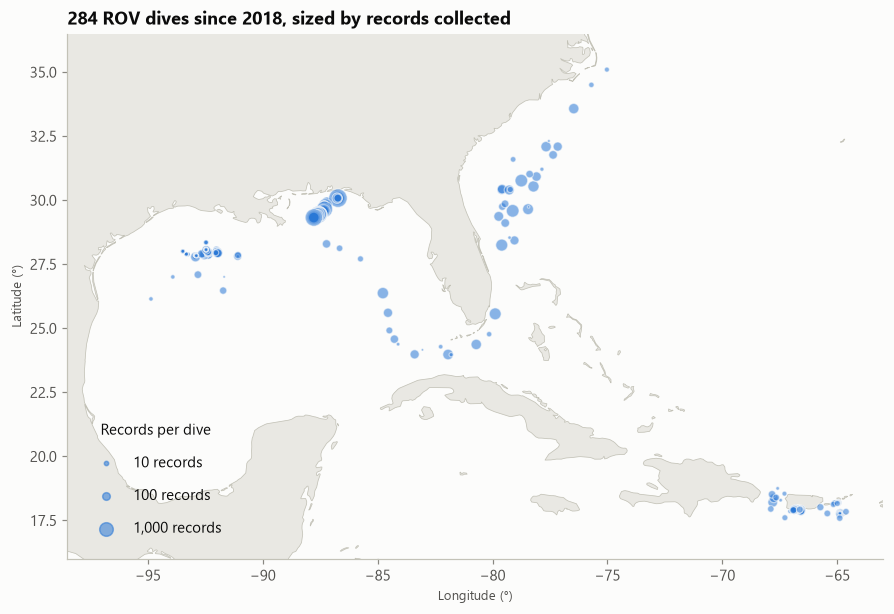

In [3]:
dives = df.groupby("event_id").agg(
    lat=("lat", "mean"),
    lon=("lon", "mean"),
    records=("catalog_num", "size"),
    region=("large_marine_ecosystem", "first"),
)

fig, ax = plt.subplots(figsize=(10, 6.2))
base_map(ax)
ax.scatter(
    dives["lon"], dives["lat"],
    s=np.sqrt(dives["records"]) * 2.5,
    color=SERIES[0], alpha=0.55, edgecolor="#fcfcfb", linewidth=0.8, zorder=2,
)
for size in (10, 100, 1000):
    ax.scatter([], [], s=np.sqrt(size) * 2.5, color=SERIES[0], alpha=0.55, label=f"{size:,} records")
ax.legend(title="Records per dive", loc="lower left", labelspacing=1.2, borderpad=1)
ax.set_title(f"{len(dives)} ROV dives since 2018, sized by records collected")
save(fig, "explore_dive_map")
plt.show()

## How effort is spread across regions and data providers

Survey effort is far from even. The two charts below count records by large marine ecosystem and by the organization that contributed them.

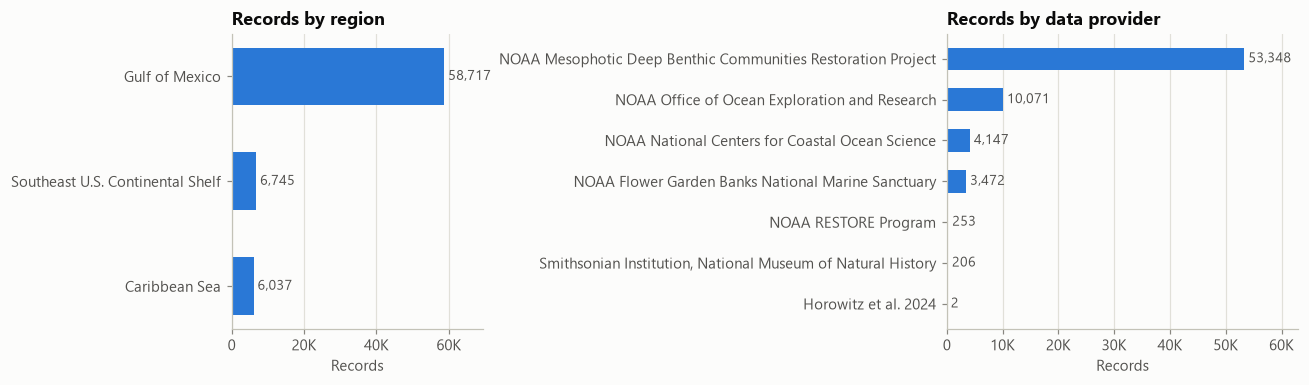

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})

region_counts = df["large_marine_ecosystem"].value_counts().sort_values()
axes[0].barh(region_counts.index, region_counts.values, color=SERIES[0], height=0.55)
axes[0].set_title("Records by region")

provider_counts = df["data_provider"].value_counts().sort_values()
labels = provider_counts.index.str.replace("NOAA, ", "NOAA ", regex=False)
axes[1].barh(labels, provider_counts.values, color=SERIES[0], height=0.55)
axes[1].set_title("Records by data provider")

for ax, counts in zip(axes, (region_counts, provider_counts)):
    ax.set_xlabel("Records")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K" if v else "0"))
    for y, v in enumerate(counts.values):
        ax.text(v, y, f" {v:,}", va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, counts.max() * 1.18)

fig.tight_layout()
save(fig, "explore_effort")
plt.show()

## Which animals were recorded

The dataset is called a coral database, but the records include sponges and fish too. The chart shows the 20 most recorded orders, colored by group.

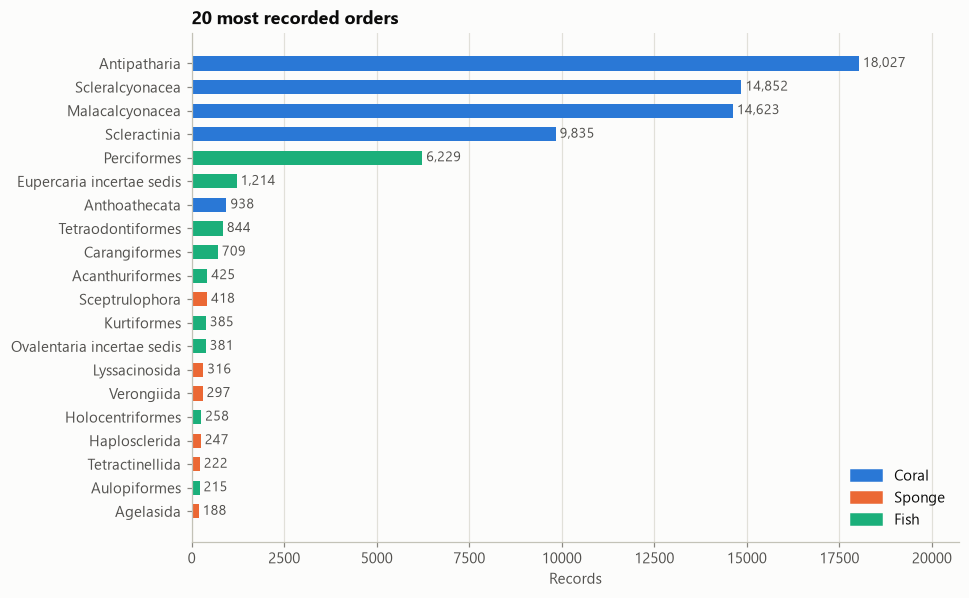

group
Coral     0.815
Fish      0.153
Sponge    0.031
Name: proportion, dtype: float64

In [5]:
GROUP_COLORS = {"Coral": SERIES[0], "Sponge": SERIES[1], "Fish": SERIES[2], "Other": MUTED_GRAY}

order_counts = (
    df.dropna(subset=["order"])
    .groupby(["order", "group"]).size()
    .reset_index(name="records")
    .nlargest(20, "records")
    .sort_values("records")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(order_counts["order"], order_counts["records"],
        color=order_counts["group"].map(GROUP_COLORS), height=0.6)
for y, v in enumerate(order_counts["records"]):
    ax.text(v, y, f" {v:,}", va="center", color=INK_2, fontsize=9)
present = [g for g in GROUP_COLORS if g in set(order_counts["group"])]
ax.legend(handles=[mpl.patches.Patch(color=GROUP_COLORS[g], label=g) for g in present], loc="lower right")
ax.set_xlim(0, order_counts["records"].max() * 1.15)
ax.set_xlabel("Records")
ax.grid(axis="y", visible=False)
ax.set_title("20 most recorded orders")
save(fig, "explore_orders")
plt.show()

df["group"].value_counts(normalize=True).round(3)

## Specimen counts

`IndividualCount` is the number of animals a record stands for. Since `Density` and `SampleAreaInSquareMeters` are almost entirely empty (see the missing-data chart below), this count is the only measure of abundance we have.

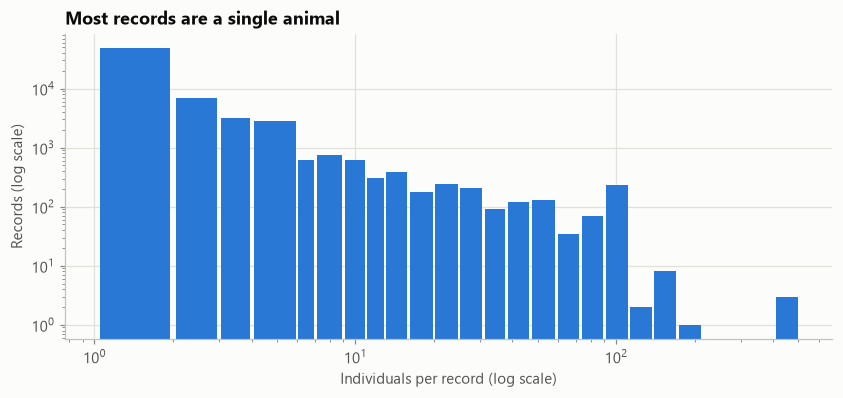

Missing counts: 7.0%
Records with count of 1: 74.5%


count    66469.000000
mean         2.583415
std          8.476684
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        500.000000
Name: count, dtype: float64

In [6]:
counts = df["count"].dropna()

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.unique(np.logspace(0, np.log10(counts.max() + 1), 30).round())
ax.hist(counts.clip(lower=1), bins=bins, color=SERIES[0], rwidth=0.9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Individuals per record (log scale)")
ax.set_ylabel("Records (log scale)")
ax.set_title("Most records are a single animal")
save(fig, "explore_individual_counts")
plt.show()

print(f"Missing counts: {df['count'].isna().mean():.1%}")
print(f"Records with count of 1: {(counts == 1).mean():.1%}")
counts.describe()

## Missing data

Before looking at environmental measurements it is worth checking how complete they are.

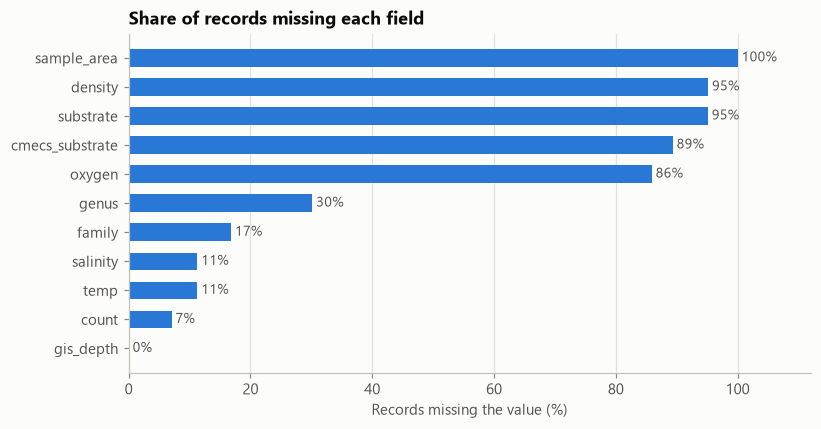

In [7]:
cols = ["count", "temp", "salinity", "oxygen", "density", "sample_area",
        "family", "genus", "substrate", "cmecs_substrate", "gis_depth"]
missing = df[cols].isna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index, missing.values * 100, color=SERIES[0], height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v * 100, y, f" {v:.0%}", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("Records missing the value (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Share of records missing each field")
save(fig, "explore_missing")
plt.show()

## Environmental measurements against depth

Temperature, salinity and oxygen were measured by sensors on the ROV, so they are only present when that sensor was running. A first look at their ranges turns up readings that cannot be real: open-ocean salinity sits around 35 PSU and dissolved oxygen cannot be negative, yet both columns contain values far outside that.

In [8]:
PLAUSIBLE = {"temp": (-2, 35), "salinity": (30, 40), "oxygen": (0, 15)}

for col, (lo, hi) in PLAUSIBLE.items():
    values = df[col].dropna()
    bad = values[(values < lo) | (values > hi)]
    print(f"{col:9} range {values.min():8.2f} to {values.max():8.2f}   "
          f"{len(bad):>4} readings outside {lo} to {hi}")

temp      range     2.90 to    23.40      0 readings outside -2 to 35
salinity  range    34.40 to  1645.30      1 readings outside 30 to 40
oxygen    range   -49.60 to     7.60      1 readings outside 0 to 15


Those readings are sensor faults or placeholder values, so they are treated as missing in the plots below (and should be in any model that uses these columns). Plotting each measurement against depth then shows both its structure and how much of the data it covers.

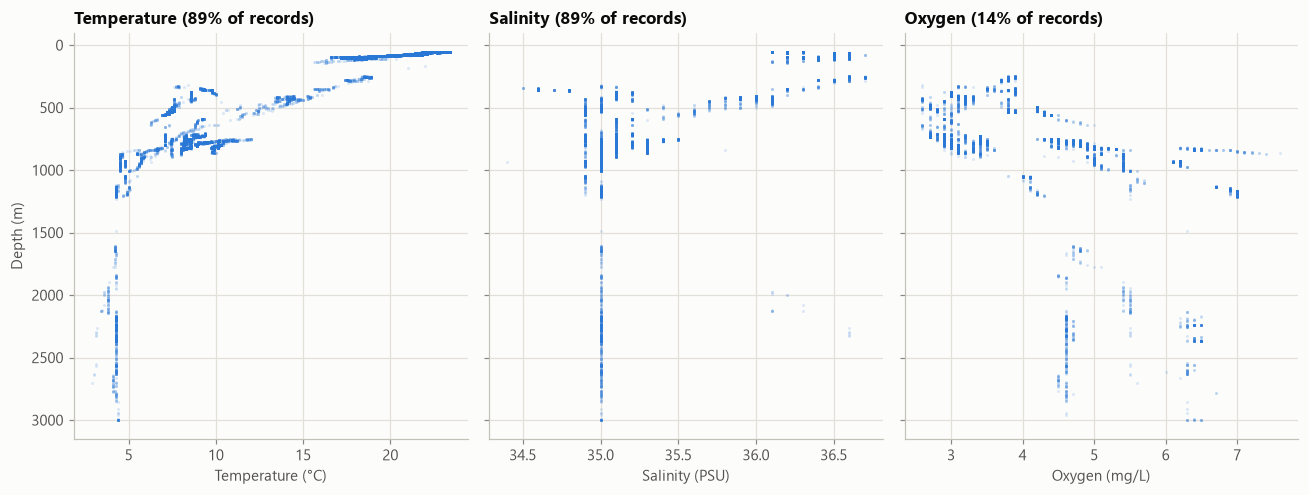

In [9]:
measures = [("temp", "Temperature (°C)"), ("salinity", "Salinity (PSU)"), ("oxygen", "Oxygen (mg/L)")]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, (col, label) in zip(axes, measures):
    sub = df[[col, "depth"]].dropna()
    sub = sub[sub[col].between(*PLAUSIBLE[col])]
    ax.scatter(sub[col], sub["depth"], s=4, color=SERIES[0], alpha=0.15, linewidth=0, rasterized=True)
    ax.set_xlabel(label)
    ax.set_title(f"{label.split(' (')[0]} ({len(sub) / len(df):.0%} of records)", fontsize=11)
axes[0].set_ylabel("Depth (m)")
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "explore_env_vs_depth")
plt.show()

## Depth by region

Depth is complete for every record and is expected to be one of the strongest drivers of which corals live where.

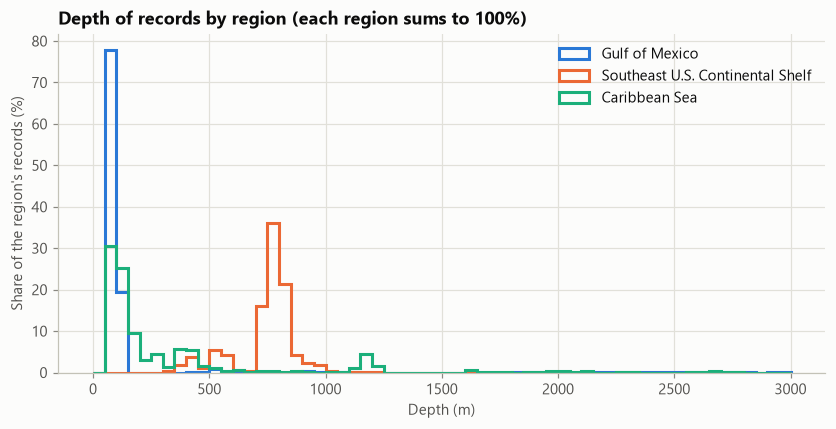

,count,mean,std,min,25%,50%,75%,max
large_marine_ecosystem,,,,,,,,
Caribbean Sea,6037.0,310.0,427.0,50.0,92.0,134.0,356.0,2779.0
Gulf of Mexico,58717.0,113.0,238.0,52.0,67.0,74.0,98.0,3000.0
Southeast U.S. Continental Shelf,6745.0,740.0,128.0,328.0,727.0,766.0,807.0,1232.0


In [10]:
regions = df["large_marine_ecosystem"].value_counts().index

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, df["depth"].max() + 50, 50)
for i, region in enumerate(regions):
    depths = df.loc[df["large_marine_ecosystem"] == region, "depth"]
    ax.hist(depths, bins=bins, weights=np.full(len(depths), 100 / len(depths)),
            histtype="step", linewidth=2, color=SERIES[i], label=region)
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Share of the region's records (%)")
ax.legend()
ax.set_title("Depth of records by region (each region sums to 100%)")
save(fig, "explore_depth_by_region")
plt.show()

df.groupby("large_marine_ecosystem")["depth"].describe().round(0)

## How much each dive contributes

The clustering treats each survey event (a dive) as one sample of a community, described by which coral families were recorded on it, so the number of coral records and families per dive matters. Dives are identified by survey ID and event ID together, as in the clustering.

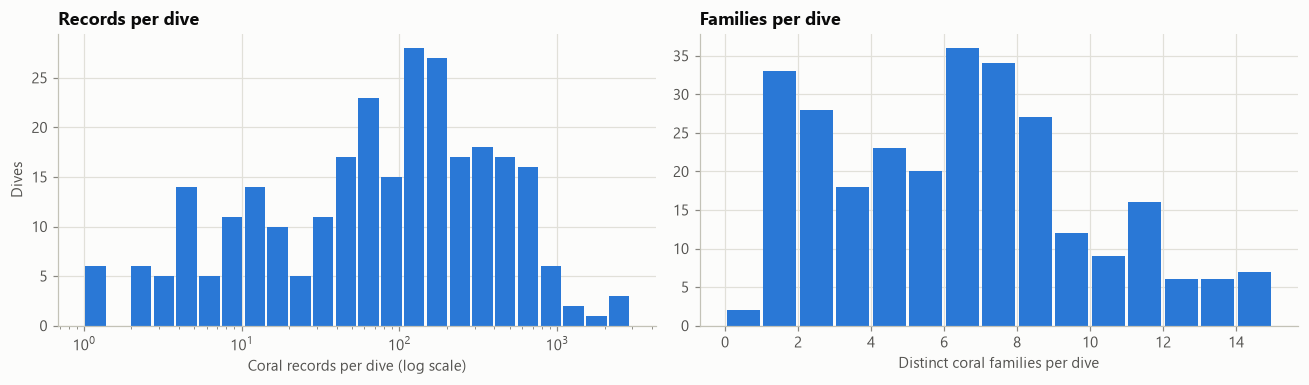

,records,families
count,277.0,277.0
mean,210.3,5.9
std,345.9,3.5
min,1.0,0.0
25%,19.0,3.0
50%,96.0,6.0
75%,255.0,8.0
max,2912.0,14.0


In [11]:
per_dive = df[df["group"] == "Coral"].groupby(["survey_id", "event_id"]).agg(
    records=("catalog_num", "size"),
    families=("family", "nunique"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(per_dive["records"], bins=np.logspace(0, np.log10(per_dive["records"].max()), 25),
             color=SERIES[0], rwidth=0.9)
axes[0].set_xscale("log")
axes[0].set_xlabel("Coral records per dive (log scale)")
axes[0].set_ylabel("Dives")
axes[0].set_title("Records per dive")
axes[1].hist(per_dive["families"], bins=range(0, per_dive["families"].max() + 2),
             color=SERIES[0], rwidth=0.9)
axes[1].set_xlabel("Distinct coral families per dive")
axes[1].set_title("Families per dive")
fig.tight_layout()
save(fig, "explore_per_dive")
plt.show()

per_dive.describe().round(1)

## What this means for the clustering

The first thing these figures show is how uneven the sampling is. Most of the 284 dives cluster in a few places: the mesophotic reefs south of the Mississippi delta, the Flower Garden Banks in the northwest Gulf, the Blake Plateau off Florida and Georgia, and the shelf around Puerto Rico and the Virgin Islands. The Gulf of Mexico contributes about four of every five records, and a single program, the Mesophotic Deep Benthic Communities Restoration Project, contributes about three of every four. Any method that treats every record equally will mostly learn about the northern Gulf at 60 to 100 m. This is why the clustering describes each survey event by which coral families were recorded on it rather than by raw record counts, and why model evaluation holds out whole areas instead of random records.

The regions also cover very different depths. Gulf records sit almost entirely between 50 and 150 m (the 50 m floor comes from the query's `ShallowFlag=0` filter), the Southeast shelf records cluster around 700 to 800 m, and the Caribbean spans everything from 50 m to nearly 3,000 m. Region and depth are therefore tangled together, and a community that appears only in one region may really be a depth signal. Temperature makes the same point from another angle: it falls steadily from about 23 °C near 50 m to about 4 °C below 1,000 m, so depth and temperature carry much of the same information. A later prediction stage will need to account for that overlap rather than count the two as independent evidence. Depth is also tangled with who collected the data: below about 500 m, nearly every dive comes from NOAA's Office of Ocean Exploration and Research, so a deep-water pattern cannot be told apart from a pattern in that one program's surveys.

About 15% of records are fish and 3% are sponges. The community analysis uses corals only: fish are dropped because they move between habitats, and sponges are left out so the profiles describe coral communities. Abundance would have to come from `IndividualCount`, since density and sample area are almost entirely empty, and that count is 1 for three quarters of records, so much of the information about a community is in which taxa are present rather than how many individuals were counted. That is why the clustering works from family presence and absence. Among the environmental variables, temperature and salinity are available for about nine in ten records, but oxygen and substrate are missing for most of them and cannot be used as features without filling them from outside sources such as Bio-Oracle. Finally, the salinity and oxygen columns each contain an impossible reading that has to be treated as missing before either column is used.